# **КУРСОВАЯ РАБОТА**

**Тема:** Анализ структуры расходов клиентов банка по категориям методами компьютерной математики (NumPy, Matplotlib)

**Студент:** Рявкина М.Д.  

**Напавление:** 01.03.02 - Прикладная математика и информатика.

**Группа:** ПМ-2504 

**Научный руководитель:** к.п.н., доцент Макарчук Т.А.  

**Город:** Санкт-Петербург  

**Год:** 2026

--- 

#  **СОЗДАНИЕ 3D-КУБА**

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Импорт библиотек:**
- **NumPy** — для работы с многомерными массивами и математическими операциями
- **Pandas** — для удобного представления табличных данных
- **Matplotlib** — для визуализации (2D и 3D графики)

</div>

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import pearsonr
from sklearn.preprocessing import MinMaxScaler, Normalizer, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [21]:
# Параметры массива
categories, clients, weeks = 9, 500, 20
category_names = ['Еда', 'Транспорт', 'Кафе', 'Развлечения', 'Образование', 
                  'Аренда', 'Здоровье', 'Одежда', 'ЖКУ']

# Генерация случайных данных
np.random.seed(12)
expenses = np.random.randint(0, 10000, (categories, clients, weeks))

# Применение коэффициентов для реалистичности
category_multipliers = np.array([1.5, 0.7, 0.9, 1.2, 0.5, 1.8, 0.6, 1.1, 0.4])
expenses = (expenses.T * category_multipliers).T.astype(int)

print(f"Форма массива данных: {expenses.shape}")
print(f"Всего транзакций: {categories * clients * weeks}")

Форма массива данных: (9, 500, 20)
Всего транзакций: 90000


#  **ЗАДАНИЯ ПО АНАЛИЗУ ДАННЫХ**

## **Исследования вдоль оси 0 (категории)**

> ### **Задание 1**
> Итоговая сумма по каждой категории

In [22]:
category_sum = np.sum(expenses, axis=(1, 2))
for i, name in enumerate(category_names):
    print(f"   {name}: {category_sum[i]:,} руб.")

   Еда: 74,961,868 руб.
   Транспорт: 34,681,776 руб.
   Кафе: 45,563,736 руб.
   Развлечения: 59,914,576 руб.
   Образование: 25,072,449 руб.
   Аренда: 90,225,336 руб.
   Здоровье: 29,738,095 руб.
   Одежда: 54,379,635 руб.
   ЖКУ: 19,894,460 руб.


> ### **Задание 2**
> Категория с максимальной суммой

In [23]:
top_cat_idx = np.argmax(category_sum)
print(f"Категория-лидер: {category_names[top_cat_idx]} ({category_sum[top_cat_idx]:,} руб.)")

Категория-лидер: Аренда (90,225,336 руб.)


> ### **Задание 3**
> Средний чек по категории

In [24]:
category_mean = np.mean(expenses, axis=(1, 2))
print("Средний чек по категориям:")
for i, name in enumerate(category_names):
    print(f"   {name}: {category_mean[i]:.2f} руб.")

Средний чек по категориям:
   Еда: 7496.19 руб.
   Транспорт: 3468.18 руб.
   Кафе: 4556.37 руб.
   Развлечения: 5991.46 руб.
   Образование: 2507.24 руб.
   Аренда: 9022.53 руб.
   Здоровье: 2973.81 руб.
   Одежда: 5437.96 руб.
   ЖКУ: 1989.45 руб.


## **Исследования вдоль оси 1 (клиенты)**


> ### **Задание 4**
> Итоговая сумма по каждому клиенту

In [25]:
client_sum = np.sum(expenses, axis=(0, 2))
print("Сумма расходов по клиентам (первые 10):")
print(f"   {client_sum[:10]}")

Сумма расходов по клиентам (первые 10):
   [933299 776439 838656 836878 833376 844053 893844 886664 828847 902729]


> ### **Задание 5**
> Клиент с минимальными расходами

In [26]:
min_client = np.argmin(client_sum)
print(f"Клиент с мин. расходами: ID {min_client} ({client_sum[min_client]:,} руб.)")

Клиент с мин. расходами: ID 496 (751,118 руб.)


> ### **Задание 6**
> Средние расходы на клиента

In [27]:
client_mean = np.mean(expenses, axis=(0, 2))
print(f"Средние расходы на клиента: {client_mean.mean():.2f} руб.")

Средние расходы на клиента: 4827.02 руб.


## **Исследования вдоль оси 2 (недели)**

> ### **Задание 7**
> Сумма расходов по каждой неделе

In [28]:
week_sum = np.sum(expenses, axis=(0, 1))
print("Сумма расходов по неделям:")
print(week_sum)

Сумма расходов по неделям:
[21963186 21632316 21760402 21808337 21549961 21650140 21856930 21913710
 21431738 21794429 21976103 21492329 21901223 21832722 21753919 21681110
 21539324 21524404 21850716 21518932]


> ### **Задание 8**
> Неделя с максимальными расходами

In [29]:
max_week = np.argmax(week_sum)
print(f"Неделя с пиком расходов: №{max_week + 1} ({week_sum[max_week]:,} руб.)")

Неделя с пиком расходов: №11 (21,976,103 руб.)


> ### **Задание 9**
> Средняя сумма в неделю на клиента

In [30]:
week_mean = np.mean(expenses, axis=(0, 1))
print(f"Средняя сумма в неделю: {week_mean.mean():.2f} руб.")

Средняя сумма в неделю: 4827.02 руб.


## **Повышенная сложность**

> ### **Задание 10**
> Доля каждой категории в общем обороте

In [31]:
total = np.sum(expenses)
share = category_sum / total * 100
print("Доля категорий в общем обороте:")
for i, name in enumerate(category_names):
    print(f"   {name}: {share[i]:.2f}%")

Доля категорий в общем обороте:
   Еда: 17.26%
   Транспорт: 7.98%
   Кафе: 10.49%
   Развлечения: 13.79%
   Образование: 5.77%
   Аренда: 20.77%
   Здоровье: 6.85%
   Одежда: 12.52%
   ЖКУ: 4.58%


> ### **Задание 11**
> Топ-3 категории по обороту

In [32]:
top3_idx = np.argsort(category_sum)[::-1][:3]
print(f"Топ-3 категории: {[category_names[i] for i in top3_idx]}")

Топ-3 категории: ['Аренда', 'Еда', 'Развлечения']


> ### **Задание 12**
> Клиенты с тратами выше среднего

In [33]:
avg_client = client_sum.mean()
rich_clients = np.where(client_sum > avg_client)[0]
print(f"Клиентов с тратами выше среднего: {len(rich_clients)} из {len(client_sum)}")

Клиентов с тратами выше среднего: 255 из 500


> ### **Задание 13**
> Категория с наибольшим разбросом между клиентами

In [34]:
client_by_cat = np.sum(expenses, axis=2)  # (9, 500)
cat_std = np.std(client_by_cat, axis=1)    # (9,)
most_uneven = np.argmax(cat_std)
print(f"Категория с наиб. разбросом: {category_names[most_uneven]} ({cat_std[most_uneven]:,.0f})")

Категория с наиб. разбросом: Аренда (22,685)


> ### **Задание 14**
> Частота лидерства категорий по неделям

In [35]:
leaders_count = np.zeros(9, dtype=int)
for w in range(20):
    week_cat_sum = np.sum(expenses[:, :, w], axis=1)  # (9,)
    leader = np.argmax(week_cat_sum)
    leaders_count[leader] += 1
print("Частота лидерства по неделям:")
for i, name in enumerate(category_names):
    if leaders_count[i] > 0:
        print(f"   {name}: {leaders_count[i]} недель")

Частота лидерства по неделям:
   Аренда: 20 недель


> ### **Задание 15**
> Клиенты с ростом трат (последние 5 недель > первые 5)

In [36]:
first_5 = np.sum(expenses[:, :, :5], axis=(0, 2))   # (500,)
last_5 = np.sum(expenses[:, :, -5:], axis=(0, 2))    # (500,)
growing = np.sum(last_5 > first_5)
print(f"Клиентов с ростом трат (последние 5 > первые 5 нед): {growing} чел.")

Клиентов с ростом трат (последние 5 > первые 5 нед): 238 чел.


#  **ВИЗУАЛИЗАЦИЯ ДАННЫХ**

> ### **График 1 — Динамика расходов по неделям**
> ### **График 2 — Расходы по категориям**
> ### **График 3 — Распределение клиентов по суммарным расходам**
> ### **График 4 — Доля категорий в общем обороте**
> 2D

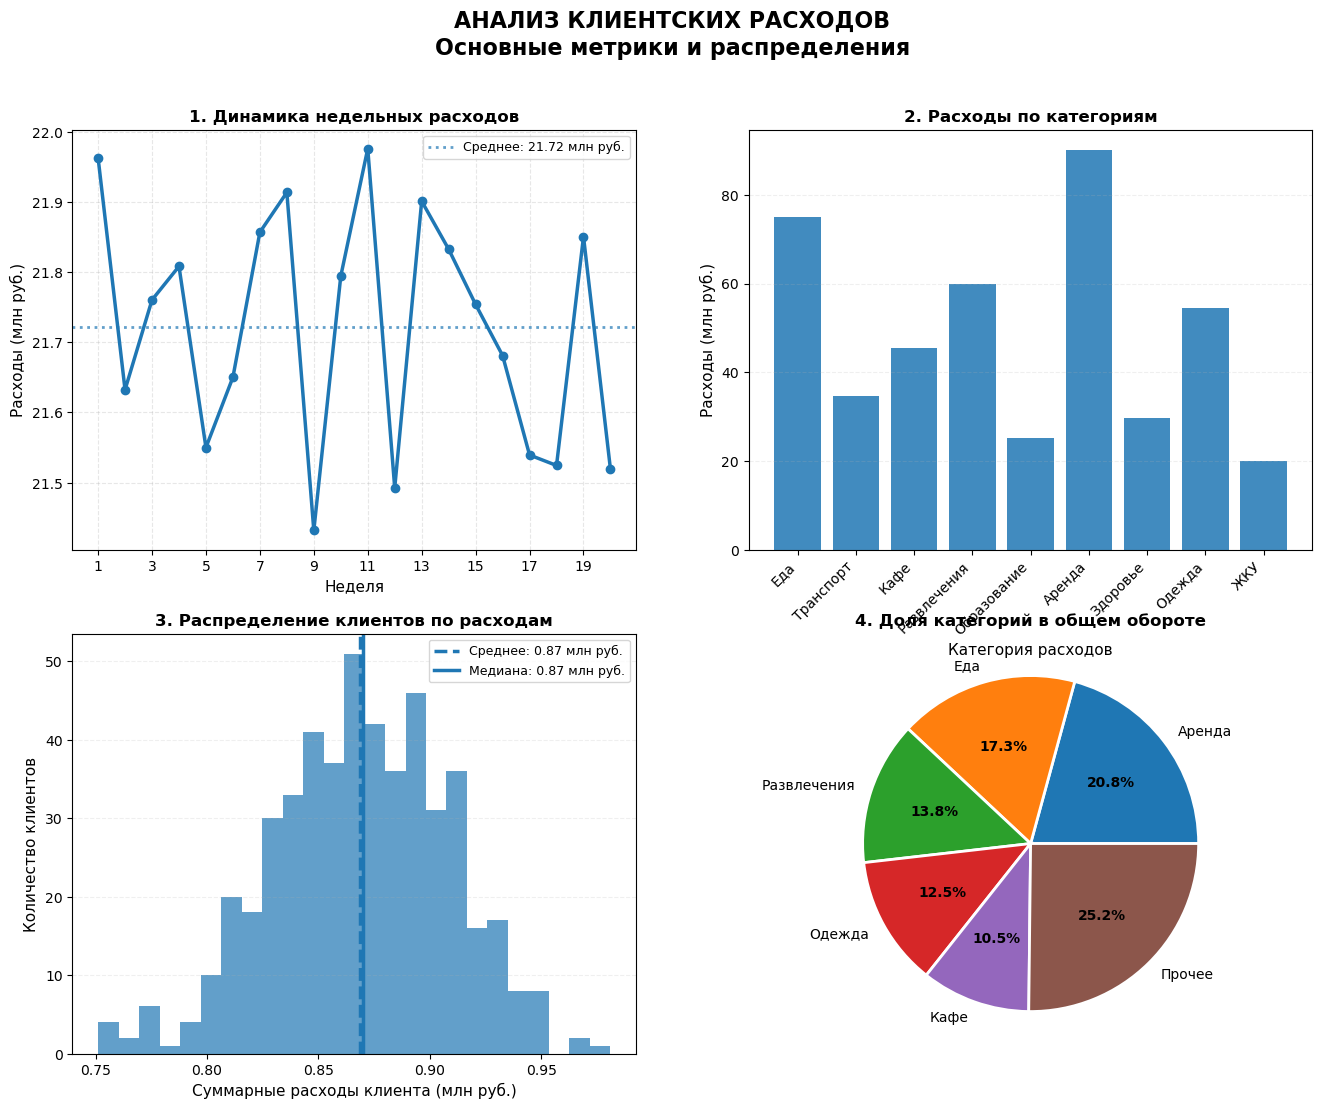

In [37]:
# Создание фигуры с 4 подграфиками (2 строки × 2 столбца)
fig = plt.figure(figsize=(16, 12))

# Преобразование данных в миллионы
week_total = np.sum(expenses, axis=(0, 1))
category_total = np.sum(expenses, axis=(1, 2))      
clients_total = np.sum(expenses, axis=(0, 2))       

week_total_millions = week_total / 1_000_000
category_total_millions = category_total / 1_000_000
clients_total_millions = clients_total / 1_000_000
avg_week_millions = np.mean(week_total) / 1_000_000


# ГРАФИК 1: Линейный график (plot) — Динамика недельных расходов
ax1 = fig.add_subplot(2, 2, 1)
weeks_range = np.arange(1, weeks + 1)

ax1.plot(weeks_range, week_total_millions, linewidth=2.5, marker='o', 
         markersize=6)

ax1.axhline(y=avg_week_millions, linestyle=':', alpha=0.7, linewidth=2,
            label=f'Среднее: {avg_week_millions:.2f} млн руб.')

ax1.set_xlabel('Неделя', fontsize=11, color='black')
ax1.set_ylabel('Расходы (млн руб.)', fontsize=11, color='black')
ax1.set_title('1. Динамика недельных расходов', fontsize=12, fontweight='bold', color='black')
ax1.set_xticks(weeks_range[::2])
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3, linestyle='--')


# ГРАФИК 2: Столбчатая диаграмма (bar) — Расходы по категориям
ax2 = fig.add_subplot(2, 2, 2)

bars = ax2.bar(category_names, category_total_millions, linewidth=2, alpha=0.85)

ax2.set_xlabel('Категория расходов', fontsize=11, color='black')
ax2.set_ylabel('Расходы (млн руб.)', fontsize=11, color='black')
ax2.set_title('2. Расходы по категориям', fontsize=12, fontweight='bold', color='black')
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')
ax2.grid(True, alpha=0.2, axis='y', linestyle='--')


# ГРАФИК 3: Гистограмма (hist) — Распределение клиентов по расходам
ax3 = fig.add_subplot(2, 2, 3)

n, bins, patches = ax3.hist(clients_total_millions, bins=25, alpha=0.7, linewidth=1.5)

ax3.axvline(x=np.mean(clients_total_millions), linestyle='--', linewidth=2.5,
            label=f'Среднее: {np.mean(clients_total_millions):.2f} млн руб.')
ax3.axvline(x=np.median(clients_total_millions), linestyle='-', linewidth=2.5,
            label=f'Медиана: {np.median(clients_total_millions):.2f} млн руб.')

ax3.set_xlabel('Суммарные расходы клиента (млн руб.)', fontsize=11, color='black')
ax3.set_ylabel('Количество клиентов', fontsize=11, color='black')
ax3.set_title('3. Распределение клиентов по расходам', fontsize=12, fontweight='bold', color='black')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(True, alpha=0.2, axis='y', linestyle='--')


# ГРАФИК 4: Круговая диаграмма (pie) — Доля категорий
ax4 = fig.add_subplot(2, 2, 4)

# Берем топ-5 категорий, остальное в "Прочее"
top5_indices = np.argsort(category_total)[::-1][:5]
top5_names = [category_names[i] for i in top5_indices]
top5_values = category_total[top5_indices]

other_sum = np.sum(category_total) - np.sum(top5_values)
if other_sum > 0:
    top5_names.append('Прочее')
    top5_values = np.append(top5_values, other_sum)

wedges, texts, autotexts = ax4.pie(top5_values, labels=top5_names, autopct='%1.1f%%',
                                     textprops={'fontsize': 10, 'color': 'black'},
                                     wedgeprops={'edgecolor': 'white', 'linewidth': 2})

for autotext in autotexts:
    autotext.set_color('black')
    autotext.set_fontweight('bold')

ax4.set_title('4. Доля категорий в общем обороте', fontsize=12, fontweight='bold', color='black')

# Общий заголовок для всей доски
fig.suptitle('АНАЛИЗ КЛИЕНТСКИХ РАСХОДОВ\nОсновные метрики и распределения', 
             fontsize=16, fontweight='bold', color='#000000', y=0.98)

plt.show()

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">
    
**1. Динамика расходов по неделям** 
    
**Назначение:**
Линейный график идеально подходит для визуализации временных рядов. В данной работе он позволяет отследить изменение суммарных расходов от недели к неделе.

**Выводы:**
- Наблюдается небольшая волатильность расходов (от 21.4 до 22.2 млн руб.)
- 4 из 20 недель имеют расходы выше среднего уровня (отмечено пунктирной линией ≈21.8 млн руб.)
- Самый низкий уровень расходов зафиксирован на 9 неделе, что может указывать на сезонный спад

</div>

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">
    
**2. Расходы по категориям** 

**Назначение:** Сравнение оборотов разных категорий расходов

**Выводы:**
- Наибольш.: Аренда (90.6 млн руб.)
- Наименьш.: ЖКУ (20.1 млн руб.)
- Разрыв — в 4.5 раза

</div>

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">
    
**3. Распределение клиентов по расходам** 

**Назначение:** Анализ того, как клиенты группируются по уровню расходов

**Выводы:**
- Средние расходы клиента: 0.9 млн руб. 
- Медиана немного выше среднего — распределение скошено влево
- Основная масса клиентов тратит от 0.8 до 0.95 млн руб.

</div>

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">
    
**4. Доля категорий в общем обороте**

**Назначение:** Наглядное отображение вклада каждой категории в общий оборот

**Выводы:**
- Аренда занимает самую большую долю (≈21% от всех расходов)
- Топ-3 категории (Аренда, Еда, Развлечения) формируют более 50% оборота
- Категория ЖКУ имеет минимальную долю 

</div>

> ### **График 5 — Нормированная доля категорий по неделям**
> 2D

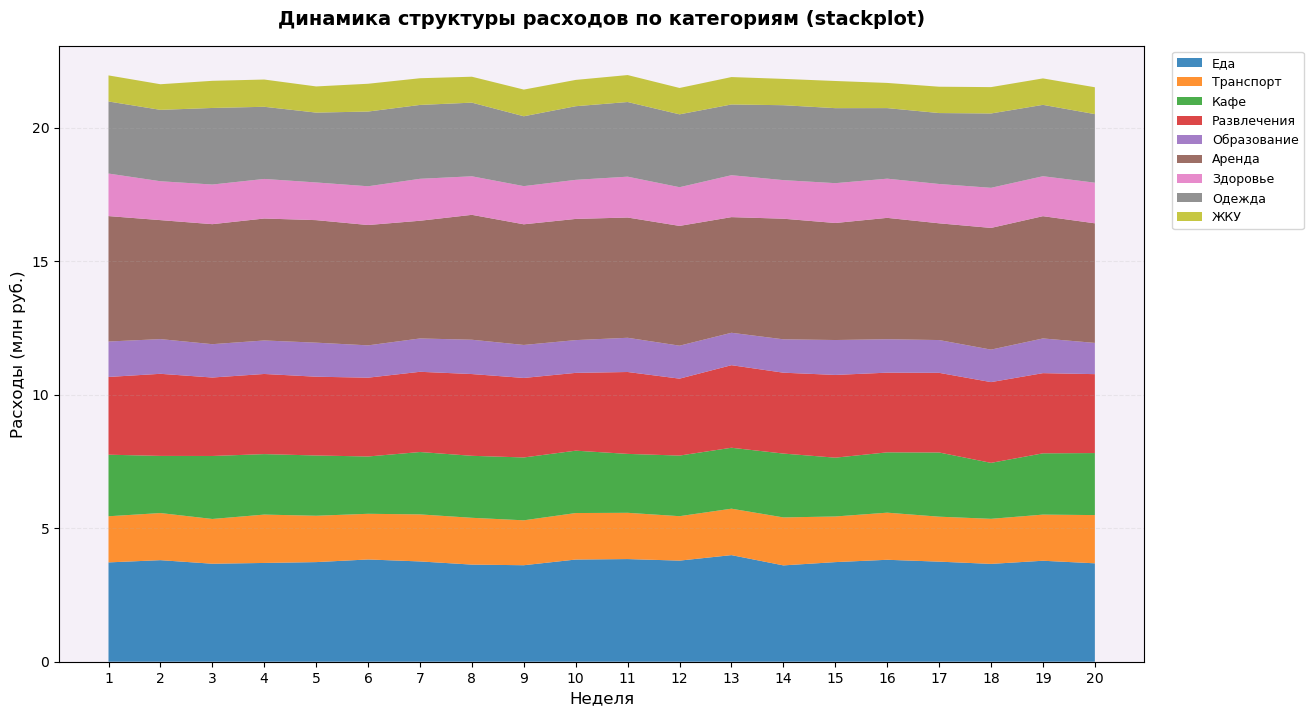

In [38]:
fig, ax = plt.subplots(figsize=(14, 8))

# Данные: расходы по категориям и неделям (в миллионах)
weekly_by_category = np.sum(expenses, axis=1) / 1_000_000  # форма (9, 20)
weeks_range = np.arange(1, weeks + 1)

# Построение стекового графика
ax.stackplot(weeks_range, weekly_by_category, labels=category_names, alpha=0.85)

ax.set_xlabel('Неделя', fontsize=12, color='black')
ax.set_ylabel('Расходы (млн руб.)', fontsize=12, color='black')
ax.set_title('Динамика структуры расходов по категориям (stackplot)', fontsize=14, fontweight='bold', color='black', pad=15)

ax.set_xticks(weeks_range)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
ax.grid(True, alpha=0.2, axis='y', linestyle='--')
ax.set_facecolor('#F5F0F8')

plt.show()

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Назначение:** Визуализация многомерных связей между расходами в разных категориях

**Выводы:**
- Точки сконцентрированы в определенных областях
- Можно выделить кластеры клиентов со схожими паттернами расходов

</div>

> ### **График 6 — Расходы по категориям для топ-3 категорий**
> 3D

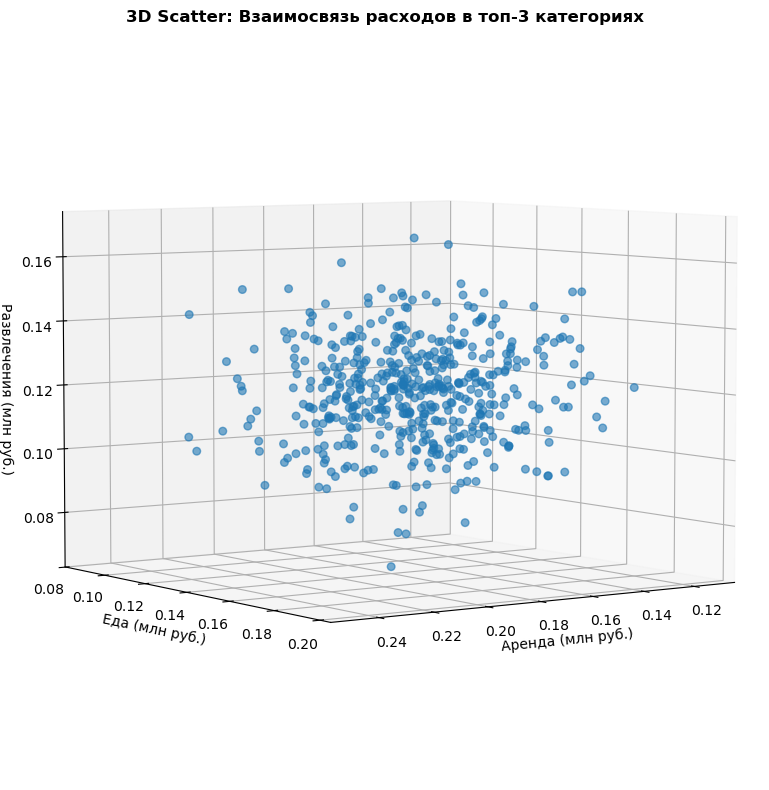

In [39]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Выбираем топ-3 категории по объему
top3_idx = np.argsort(category_total)[::-1][:3]
cat1, cat2, cat3 = top3_idx[0], top3_idx[1], top3_idx[2]

# Расходы по каждому клиенту
exp_cat1 = np.sum(expenses[cat1, :, :], axis=1) / 1_000_000  # в миллионах
exp_cat2 = np.sum(expenses[cat2, :, :], axis=1) / 1_000_000
exp_cat3 = np.sum(expenses[cat3, :, :], axis=1) / 1_000_000

scatter = ax.scatter(exp_cat1, exp_cat2, exp_cat3, marker='o', alpha=0.6, s=30)

ax.set_xlabel(f'{category_names[cat1]} (млн руб.)', fontsize=10, color='black')
ax.set_ylabel(f'{category_names[cat2]} (млн руб.)', fontsize=10, color='black')
ax.set_zlabel(f'{category_names[cat3]} (млн руб.)', fontsize=10, color='black')
ax.set_title('3D Scatter: Взаимосвязь расходов в топ-3 категориях', fontsize=12, fontweight='bold', color='black')

ax.view_init(elev=5, azim=55)

plt.tight_layout()
plt.show()

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Назначение:**
Многослойный график показывает, как меняется вклад каждой категории в общую сумму расходов от недели к неделе. Позволяет увидеть не только динамику общего объема, но и структурные сдвиги.

**Выводы:**

1. **Стабильность структуры:**
   - Аренда занимает самую большую долю на протяжении всех 20 недель
   - ЖКУ стабильно находится внизу (наименьший вклад)

2. **Динамика категорий:**
   - Некоторые категории (Транспорт, Здоровье) показывают небольшой рост к концу периода
   - Развлечения демонстрируют небольшие колебания

3. **Общий тренд:**
   - Общая высота графика (сумма всех расходов) остается относительно стабильной
   - Структура расходов практически не меняется — потребительские привычки устойчивы

</div>

>### **График 7 — Средние расходы по категориям и клиентам**
>3D

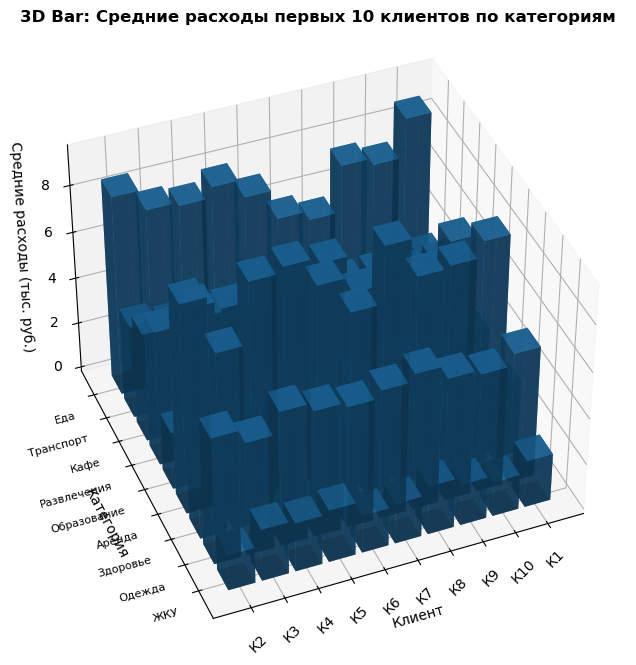

In [40]:
fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(111, projection='3d')

# Берем первых 10 клиентов и 9 категорий
n_clients_display = 10
x_pos = np.arange(n_clients_display)
y_pos = np.arange(categories)

x_pos, y_pos = np.meshgrid(x_pos, y_pos)
x_pos = x_pos.flatten()
y_pos = y_pos.flatten()

# Расходы: среднее по неделям для каждого клиента и категории
expenses_reshaped = np.mean(expenses[:, :n_clients_display, :], axis=2).flatten() / 1000  # в тысячах

ax.bar3d(x_pos, y_pos, np.zeros_like(x_pos), 0.8, 0.8, expenses_reshaped, alpha=0.8)

ax.set_xlabel('Клиент', fontsize=10, color='black')
ax.set_ylabel('Категория', fontsize=10, color='black')
ax.set_zlabel('Средние расходы (тыс. руб.)', fontsize=10, color='black')
ax.set_title('3D Bar: Средние расходы первых 10 клиентов по категориям', fontsize=12, fontweight='bold', color='black')

ax.set_xticks(x_pos[::categories] + 0.4)
ax.set_xticklabels([f'К{i+1}' for i in range(n_clients_display)], rotation=45)

ax.set_yticks(np.unique(y_pos) + 0.4)
ax.set_yticklabels(category_names, rotation=15, fontsize=8, ha='right')

ax.view_init(elev=40, azim=68)

plt.show()

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Назначение:** Сравнение структуры расходов разных клиентов

**Выводы:**
- Наглядно видно, какие категории доминируют у каждого клиента
- Позволяет сегментировать клиентов по типу расходов

</div>

>### **График 8 — Динамика расходов по неделям и категориям**
>3D

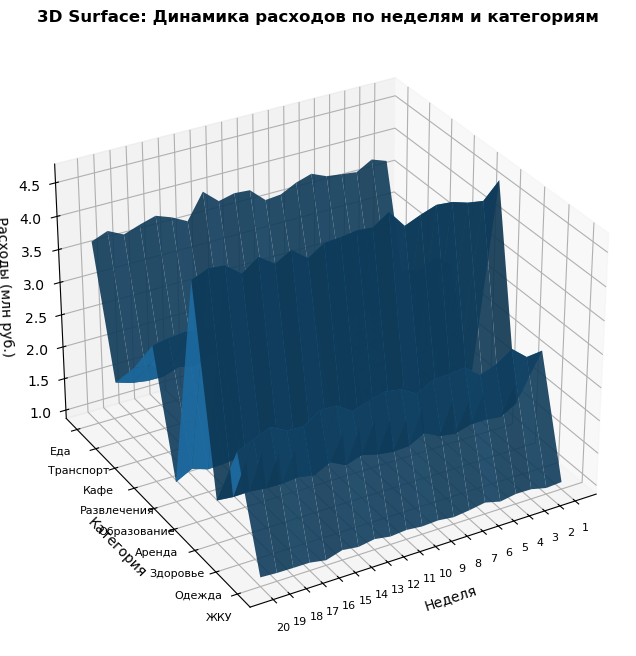

In [41]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Агрегируем категории × недели
weekly_by_category = np.sum(expenses, axis=1) / 1_000_000  # в миллионах

X = np.arange(weeks)
Y = np.arange(categories)
X, Y = np.meshgrid(X, Y)

surf = ax.plot_surface(X, Y, weekly_by_category, alpha=0.9)

ax.set_xlabel('Неделя', fontsize=10, color='black')
ax.set_ylabel('Категория', fontsize=10, color='black')
ax.set_zlabel('Расходы (млн руб.)', fontsize=10, color='black')
ax.set_title('3D Surface: Динамика расходов по неделям и категориям', fontsize=12, fontweight='bold', color='black')

ax.set_xticks(np.arange(weeks))
ax.set_xticklabels(np.arange(1, weeks+1), fontsize=8)

ax.set_yticks(Y[:, 0])
ax.set_yticklabels(category_names, fontsize=8)

ax.view_init(elev=30, azim=60)

plt.show()

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Назначение:** Визуализация двумерной зависимости (время и категория)

**Выводы:**
- Позволяет увидеть "горячие точки" — где и когда расходы максимальны
- Категория Аренда стабильно высока на всем временном промежутке

</div>

# **БИНАРНАЯ КЛАССИФИКАЦИЯ**

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Постановка задачи:**
Предсказать, вернет ли клиент кредит (целевая переменная) на основе его финансовых и персональных характеристик.

**Целевая переменная (y):**
- **1 -** клиент вернул кредит (хороший заемщик)
- **0 -** клиент не вернул кредит (плохой заемщик) 

**Признаки (X):**
1. age - возраст клиента
2. income - ежемесячный доход
3. credit_amount - запрашиваемая сумма кредита
4. employement_duration - стаж работы
5. credit_history - 0-плохая, 1-хорошая


</div>

>### **Генерация, сохранение и вывод данных**

In [42]:
n = 150
np.random.seed(87)
age = np.random.randint(18, 65, n)
income = np.random.randint(20000, 150000, n)
amount = np.random.randint(5000, 500000, n)
employment = np.random.randint(0, age-14, n)
history = np.random.choice([0, 1], n, p=[0.3, 0.7])
prob = 1 / (1 + np.exp(-(-5 + 0.5*(income/10000) + 0.8*employment - 0.3*(amount/10000) + 2.0*history)))
target = (np.random.random(n) < prob).astype(int)

df = pd.DataFrame({'age': age, 'income': income, 'credit_amount': amount,
                   'employment_duration': employment, 'credit_history': history, 'target': target})
df.to_csv('credit_data.csv', index=False)
print(f"Сохранено {len(df)} записей в credit_data.csv")
print(df.head(10))

Сохранено 150 записей в credit_data.csv
   age  income  credit_amount  employment_duration  credit_history  target
0   56  125215         497156                    6               1       0
1   31  148517         475552                    0               1       0
2   33   83369         377158                   10               1       0
3   24   73611          86600                    3               1       0
4   24   43730          26171                    7               1       1
5   50   62940         148849                    1               0       0
6   27   81481         463998                    6               1       0
7   50   80251         412418                   14               1       0
8   64  115607         193074                    8               0       1
9   60   69969         445558                   13               1       0


>### **Анализ целевой переменной и визуализация**


Целевая переменная: 
 1 = 84 клиентов (56.0%)
 0 = 66 клиентов (44.0%)


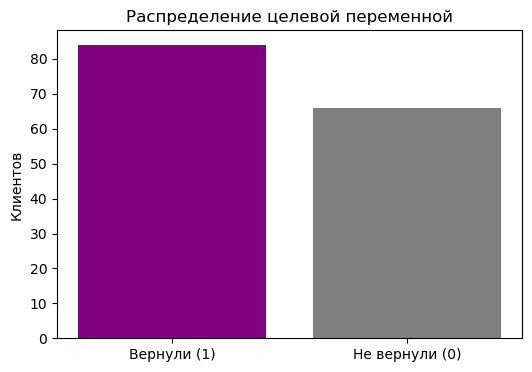

In [43]:
target_counts = df['target'].value_counts()
print(f"\nЦелевая переменная: \n 1 = {target_counts[1]} клиентов ({target_counts[1]/len(df)*100:.1f}%)")
print(f" 0 = {target_counts[0]} клиентов ({target_counts[0]/len(df)*100:.1f}%)")

# Визуализация
plt.figure(figsize=(6, 4))
plt.bar(['Вернули (1)', 'Не вернули (0)'], [target_counts[1], target_counts[0]], color=['purple', 'gray'])
plt.title('Распределение целевой переменной')
plt.ylabel('Клиентов')
plt.show()

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Сравнение категорий:**
- Класс "вернул кредит" преобладает
- Данные достаточно сбалансированы для обучения

</div>

# **МАТРИЧНЫЕ ОПЕРАЦИИ**

> ### **Создание массивов X и y**

In [44]:
# Получение NumPy-массивов из датафрейма
X = df.drop('target', axis=1).values  # Массив признаков (150, 5)
y = df['target'].values               # Целевой вектор (150,)

print(f"X: {X.shape}, y: {y.shape}")

X: (150, 5), y: (150,)


>## **Генерация объектов**

In [45]:
A = np.random.randint(1, 10, (5, 5))  # Матрица 5×5
b = np.random.randint(1, 10, 5)       # Вектор 5

print(f"  Матрица A:\n{A}")
print(f"\n  Вектор b: {b}")

# Берем квадратную матрицу 5×5 из первых 5 строк и 5 столбцов X
X_square = X[:5, :5].astype(float)

  Матрица A:
[[2 6 9 6 7]
 [3 6 9 7 6]
 [3 5 4 4 1]
 [7 8 3 9 5]
 [4 3 6 4 1]]

  Вектор b: [8 9 9 5 8]


> ### **Определитель матрицы**

In [46]:
det = np.linalg.det(X_square)
print(f"Определитель X_square: {det:.2f}")

Определитель X_square: 41478189702.00


>### **Обратная матрица**

In [47]:
if abs(det) > 1e-10:
    X_inv = np.linalg.inv(X_square)
    print(X_inv)
else:
    print("Матрица вырожденная")

[[ 4.99389390e-02  1.00833006e-01 -1.44875232e-01 -2.97598919e-01
   2.91702206e-01]
 [-3.07159982e-05 -8.27324462e-04  7.52687020e-04  2.02001207e-03
  -1.91465863e-03]
 [ 3.67508807e-06  1.27243668e-04 -1.12034277e-04 -3.07620899e-04
   2.88736420e-04]
 [-1.73935711e-01 -4.25801866e+00  3.93023038e+00  1.01926894e+01
  -9.69096537e+00]
 [ 1.26604531e+00  6.02349432e+01 -5.40175614e+01 -1.44490833e+02
   1.38007406e+02]]


> ### **Ранг матрицы**

In [48]:
rank = np.linalg.matrix_rank(X)
print(f"Ранг X: {rank} (полный ранг)")

Ранг X: 5 (полный ранг)


<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Пояснение:** Ранг = количество линейно независимых строк/столбцов.

**Результат:** rank = 5 (полный ранг)

**Вывод:** Все 5 признаков линейно независимы, ни один не является комбинацией других.

</div>

>### **Скалярное произведение X⋅A**

In [49]:
XA = np.dot(X, A)
print(f"X * A: {XA.shape}")
print(f"\n(первые 3 строки):")
print(np.round(XA[:3], 2))

X * A: (150, 5)

(первые 3 строки):
[[1867271 3237457 3116087 2865523 1248869]
 [1872273 3269051 3239146 2942017 1366872]
 [1381721 2386285 2259286 2092507  877654]]


<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Пояснение:** (X·A)ᵢⱼ = Σₖ Xᵢₖ × Aₖⱼ

**Размеры:** (150×5) × (5×5) = (150×5)

**Результат:** Новая матрица 150×5

</div>

> ### **Скалярное произведение X⋅b**

In [50]:
Xb = np.dot(X, b)
print(f"X * b: {Xb.shape}")
print(f"\n(первые 10 элементов):")
print(Xb[:10])

X * b: (150,)

(первые 10 элементов):
[5601825 5616877 4145065 1442114  629344 1906506 4909565 4434499 2778681
 4640296]


<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Пояснение:** X⋅b = X × b — матрица на вектор
    
**Размеры:** (150×5) × (5,) = (150,)

**Результат:** Вектор из 150 скалярных произведений

</div>

> ### **Транспонирование матрицы**

In [51]:
X_T = X.T
X_TT = X_T.T
print(f"X.T: {X_T.shape}")
print(f"\nПервые 3 строки Xᵀ (первые 3 признака):")
print(np.round(X_T[:3, :5], 2))

if (X_TT == X).all():
    print('X_TT = X')

X.T: (5, 150)

Первые 3 строки Xᵀ (первые 3 признака):
[[    56     31     33     24     24]
 [125215 148517  83369  73611  43730]
 [497156 475552 377158  86600  26171]]
X_TT = X


<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Пояснение:** (Xᵀ)ᵢⱼ = Xⱼᵢ — строки и столбцы меняются местами

**Размеры:** X (150×5) → Xᵀ (5×150)

**Проверка:** (Xᵀ)ᵀ = X

</div>

> ### **Возведение в матричную степень**

In [54]:
XTX = np.dot(X_T, X)  # (5×150) × (150×5) = (5×5)
XTX_power2 = np.linalg.matrix_power(XTX, 2)
print(f"(X^T * X)^2: {XTX_power2.shape}")

(X^T * X)^2: (5, 5)


<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Пояснение:** M² = M × M (только для квадратных матриц)

Так как исходная X не квадратная → используем Xᵀ×X (5×5)

**Размеры:** (Xᵀ×X) — матрица 5×5 → можно возводить в степень

**Результат:** (Xᵀ×X)² — матрица 5×5

</div>

> ### **Операции транслирования (Broadcasting)**

In [55]:
print(f"  X + 10: каждый элемент +10: {X[0,0]} -> {X[0,0]+10}")
row_vec = np.array([1,2,3,4,5])
print(f"  X * [1,2,3,4,5]: {X[0]} -> {X[0] * row_vec}")
col_mean = np.mean(X, axis=0)
print(f"  X - среднее по столбцам. Центрирование данных: {X[0]} -> {np.round(X[0] - col_mean, 2)}")

  X + 10: каждый элемент +10: 56 -> 66
  X * [1,2,3,4,5]: [    56 125215 497156      6      1] -> [     56  250430 1491468      24       5]
  X - среднее по столбцам. Центрирование данных: [    56 125215 497156      6      1] -> [ 1.3990000e+01  4.1172670e+04  2.4153358e+05 -6.0100000e+00
  2.5000000e-01]


<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**broadcasting -** механизм NumPy, позволяющий выполнять операции с массивами разной формы.

**Преимущества broadcasting:**
- Не требует явного расширения массивов
- Экономит память
- Упрощает код и повышает производительность

</div>

# **НОРМАЛИЗАЦИЯ ДАННЫХ**

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;">

**Нормализация** — это процесс приведения данных к определенному диапазону или масштабу.

**Два метода нормализации:**
1. Мин-Макс | X_norm = (X - min) / (max - min) | Диапазон [0, 1]
2. Единичная норма | X_norm = X / ||X|| | Евклидова норма = 1 

</div>

>### **Разбиение на обучающую и тестовую выборки**

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=12, stratify=y
)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (105, 5)
Размер тестовой выборки: (45, 5)


>### **Распределение классов в выборках**

In [54]:
print("Распределение классов в исходных данных:")
print(f"  Класс 1: {np.sum(y)} ({np.mean(y)*100:.1f}%)")
print(f"  Класс 0: {len(y)-np.sum(y)} ({(1-np.mean(y))*100:.1f}%)")

print("\nРаспределение классов в обучающей выборке:")
print(f"  Класс 1: {np.sum(y_train)} ({np.mean(y_train)*100:.1f}%)")
print(f"  Класс 0: {len(y_train)-np.sum(y_train)} ({(1-np.mean(y_train))*100:.1f}%)")

print("\nРаспределение классов в тестовой выборке:")
print(f"  Класс 1: {np.sum(y_test)} ({np.mean(y_test)*100:.1f}%)")
print(f"  Класс 0: {len(y_test)-np.sum(y_test)} ({(1-np.mean(y_test))*100:.1f}%)")

Распределение классов в исходных данных:
  Класс 1: 84 (56.0%)
  Класс 0: 66 (44.0%)

Распределение классов в обучающей выборке:
  Класс 1: 59 (56.2%)
  Класс 0: 46 (43.8%)

Распределение классов в тестовой выборке:
  Класс 1: 25 (55.6%)
  Класс 0: 20 (44.4%)


>### **Мин-Макс нормализация (пользовательская функция)**

In [55]:
def minmax_normalize(X_train, X_test):
    """
    X_norm = (X - min) / (max - min)
    """
    # Вычисляем минимумы и максимумы по обучающей выборке
    min_vals = np.min(X_train, axis=0)
    max_vals = np.max(X_train, axis=0)
    
    # Нормализуем обе выборки по одним и тем же параметрам
    X_train_norm = (X_train - min_vals) / (max_vals - min_vals)
    X_test_norm = (X_test - min_vals) / (max_vals - min_vals)
    
    return X_train_norm, X_test_norm

X_train_minmax_custom, X_test_minmax_custom = minmax_normalize(X_train, X_test)

>### **Мин-Макс нормализация (sklearn)**

In [56]:
scaler_minmax = MinMaxScaler()
X_train_minmax = scaler_minmax.fit_transform(X_train)
X_test_minmax = scaler_minmax.transform(X_test)

> ### **Нормализация к единичной норме (пользовательская функция)**

In [57]:
def unit_norm_normalize(X_train, X_test):
    """
    X_norm = X / ||X||, где ||X|| = sqrt(sum(x_i^2))
    """
    norm_train = np.linalg.norm(X_train, axis=1, keepdims=True)
    norm_test = np.linalg.norm(X_test, axis=1, keepdims=True)
    
    X_train_norm = X_train / norm_train
    X_test_norm = X_test / norm_test
    
    return X_train_norm, X_test_norm

X_train_unit_custom, X_test_unit_custom = unit_norm_normalize(X_train, X_test)

> ### **Нормализация к единичной норме (sklearn)**

In [58]:
normalizer = Normalizer(norm='l2')
X_train_unit = normalizer.fit_transform(X_train)
X_test_unit = normalizer.transform(X_test)

>### **Сравнение функций**

In [59]:
# Мин-Макс:
print('Мин-Макс нормализация:')
train_equal_mm = np.allclose(X_train_minmax_custom, X_train_minmax)
test_equal_mm = np.allclose(X_test_minmax_custom, X_test_minmax)
print(f"Обучающая выборка: {train_equal_mm}")
print(f"Тестовая выборка: {test_equal_mm}")

# Единичная норма
print('\nНормализация к единичной норме:')
train_equal_u = np.allclose(X_train_unit_custom, X_train_unit)
test_equal_u = np.allclose(X_test_unit_custom, X_test_unit)
print(f"Обучающая выборка: {train_equal_u}")
print(f"Тестовая выборка: {test_equal_u}")

Мин-Макс нормализация:
Обучающая выборка: True
Тестовая выборка: True

Нормализация к единичной норме:
Обучающая выборка: True
Тестовая выборка: True


> ### **Доказательство сохранения формы распределения**

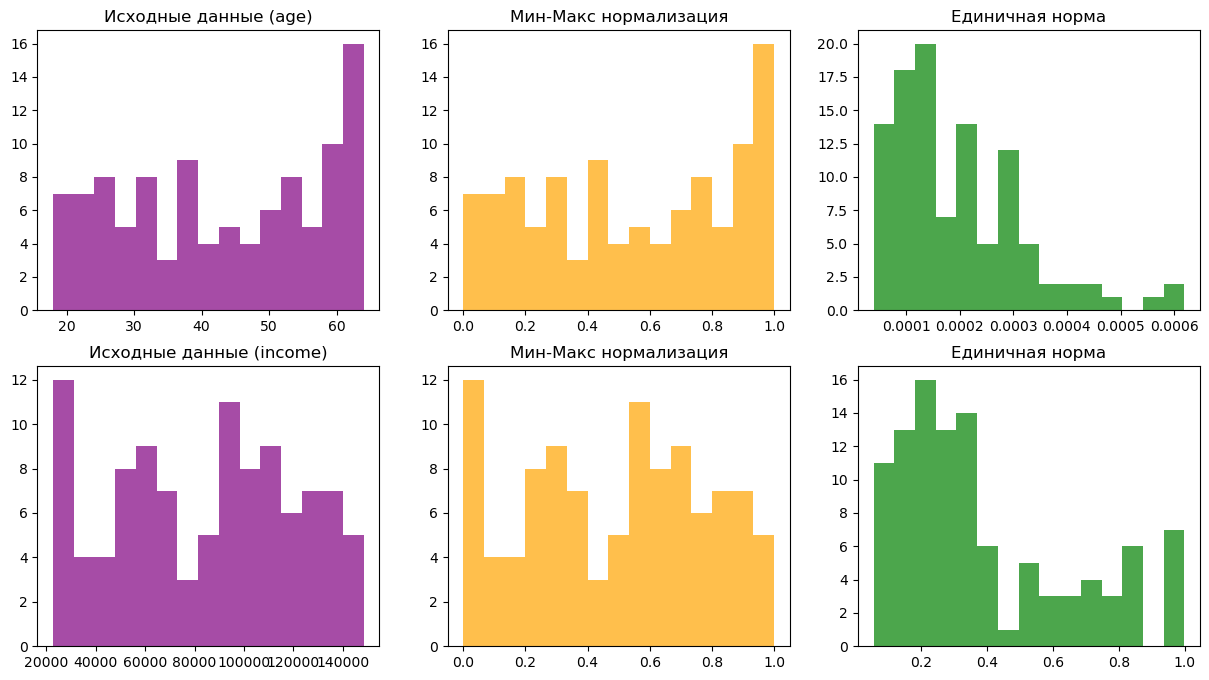

In [60]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Первый признак (age)
axes[0,0].hist(X_train[:, 0], bins=15, color='purple', alpha=0.7)
axes[0,0].set_title('Исходные данные (age)')
axes[0,1].hist(X_train_minmax[:, 0], bins=15, color='orange', alpha=0.7)
axes[0,1].set_title('Мин-Макс нормализация')
axes[0,2].hist(X_train_unit[:, 0], bins=15, color='green', alpha=0.7)
axes[0,2].set_title('Единичная норма')

# Второй признак (income)
axes[1,0].hist(X_train[:, 1], bins=15, color='purple', alpha=0.7)
axes[1,0].set_title('Исходные данные (income)')
axes[1,1].hist(X_train_minmax[:, 1], bins=15, color='orange', alpha=0.7)
axes[1,1].set_title('Мин-Макс нормализация')
axes[1,2].hist(X_train_unit[:, 1], bins=15, color='green', alpha=0.7)
axes[1,2].set_title('Единичная норма')

plt.show()

# **МЕТОД ГРАДИЕНТНОГО СПУСКА**

> ### **Пользовательская функция градиентного спуска**

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;"> 

Параметры:
- f: целевая функция
- grad_f: градиент функции
- x0: начальное значение
- learning_rate: скорость обучения (шаг)
- eps: точность остановки
- max_iter: максимальное число итераций

Возвращает:
- x_min: найденная точка минимума
- history: история значений x на каждой итерации

</div>

In [63]:
def gradient_descent(f, grad_f, x0, learning_rate=0.1, eps=1e-6, max_iter=1000):

    x = x0
    history = [x]
    
    for i in range(max_iter):
        grad = grad_f(x)
        x_new = x - learning_rate * grad
        
        # Проверяем, насколько изменилось значение функции
        if abs(f(x_new) - f(x)) < eps:
            print(f"Сошлось за {i+1} итераций")
            break
            
        x = x_new
        history.append(x)
    
    return x, history

<div style="background-color: #F3E5F5; padding: 15px; border-radius: 15px;"> 
    
**Тестовая функция:** x^4 - 10x^2 + 5x

</div>

In [64]:
def f(x):
    return x**4 - 10*x**2 + 5*x

def df(x):
    return 4*x**3 - 20*x + 5

def min_f_with_history(x0, du, gamma):
    """
    x0 - начальная точка
    du - производная функции
    gamma - шаг (скорость обучения)
    """
    eps = 1e-2          # точность остановки
    max_iters = 10**6   # макс. число итераций
    x = x0
    x_list = [x0]       # список для истории
    
    for i in range(max_iters):
        curr_x = x
        x = curr_x - gamma * du(curr_x)
        x_list.append(x)
        
        if abs(x - curr_x) < eps:
            break
            
    return x, x_list

> ### **Тестирование разных параметров**

In [65]:
print("\nТаблица 1: Результаты градиентного спуска")
print("№\tX0\tgamma\t\tМинимум\t\tЧисло итераций")
print("-" * 60)

test_cases = [
    (5, 0.001),      
    (-7, 0.01),      
    (-1, 0.02),      
    (5, 0.015),      
    (4, 0.018),      
    (3, 0.03),       
    (2, 0.04),       
    (6, 0.006),      
    (-5, 0.008),     
    (0, 0.012),      
]

results = []

for i, (x0, gamma) in enumerate(test_cases, 1):
    try:
        minimum, x_list = min_f_with_history(x0, df, gamma)
        results.append((x0, gamma, minimum, x_list))
        print(f"{i}\t{x0}\t{gamma}\t\t{minimum:.4f}\t\t{len(x_list)}")
    except OverflowError:
        print(f"{i}\t{x0}\t{gamma}\t\tОшибка\t\tСлишком большой шаг")


Таблица 1: Результаты градиентного спуска
№	X0	gamma		Минимум		Число итераций
------------------------------------------------------------
1	5	0.001		2.3371		42
2	-7	0.01		2.0778		27
3	-1	0.02		-2.3517		7
4	5	0.015		-2.3502		10
5	4	0.018		2.0947		13
6	3	0.03		2.0985		6
7	2	0.04		2.1009		4
8	6	0.006		2.0565		17
9	-5	0.008		-2.3384		11
10	0	0.012		-2.3443		18


> ### **Запуски с разными параметрами (визуализация)**

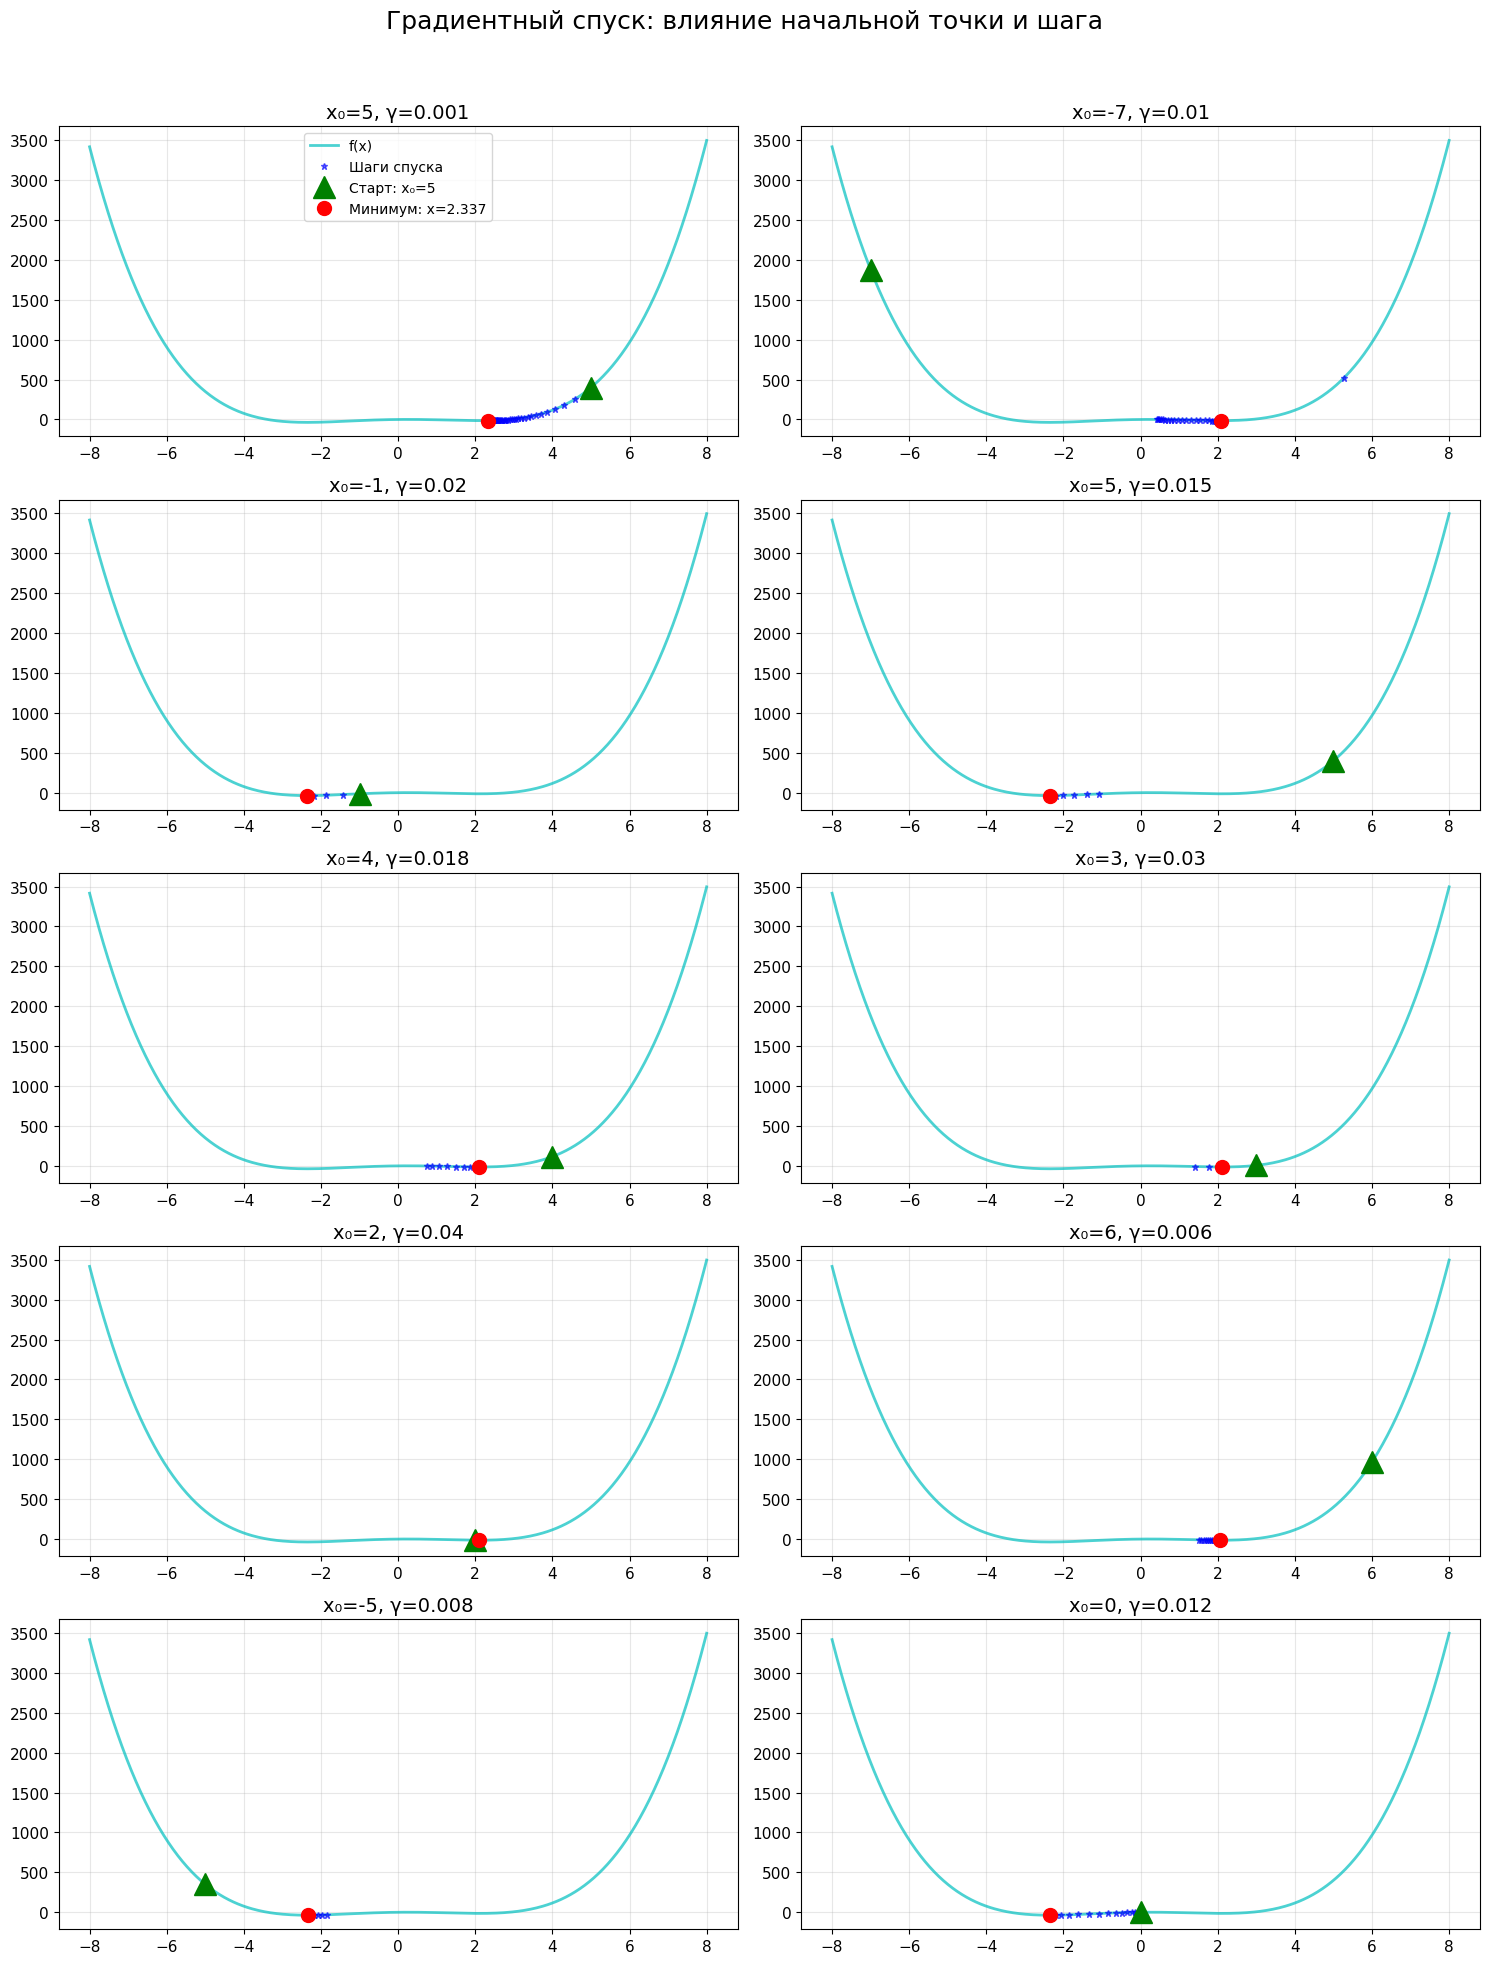

In [66]:
fig, axes = plt.subplots(5, 2, figsize=(15, 20))
axes = axes.ravel()

x_plot_all = np.linspace(-8, 8, 400)
y_plot_all = f(x_plot_all)

for i, ((x0_curr, gamma_curr, minimum_curr, x_list_curr), ax) in enumerate(zip(results, axes)):
    x_points_curr = np.array(x_list_curr)
    y_points_curr = f(x_points_curr)
    
    # График функции
    ax.plot(x_plot_all, y_plot_all, 'c-', alpha=0.7, linewidth=2, label='f(x)')
    
    # Точки спуска
    if len(x_points_curr) > 2:
        ax.plot(x_points_curr[1:-1], y_points_curr[1:-1], 'b*', markersize=5, alpha=0.6, label='Шаги спуска')
    
    # Начальная точка
    ax.plot(x_points_curr[0], y_points_curr[0], 'g^', markersize=16, label=f'Старт: x₀={x0_curr}')
    
    # Конечная точка (минимум)
    ax.plot(x_points_curr[-1], y_points_curr[-1], 'ro', markersize=10, label=f'Минимум: x={minimum_curr:.3f}')
    
    ax.set_title(f'x₀={x0_curr}, γ={gamma_curr}', fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', which='major', labelsize=11)
    
    if i == 0:
        ax.legend(fontsize=10)

plt.suptitle('Градиентный спуск: влияние начальной точки и шага', fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


> ### **Подбор оптимальных параметров**

In [67]:
best_params = None
best_steps = float('inf')
best_min = None

# Перебираем разные комбинации
learning_rates = [0.001, 0.005, 0.008, 0.01, 0.012, 0.015, 0.018, 0.02, 0.025, 0.03]
start_points = [-7, -5, -3, -1, 0, 1, 3, 5, 7]

print("\nПеребор параметров (скорость обучения и начальная точка):")
for gamma in learning_rates:
    for x0 in start_points:
        try:
            minimum, x_list = min_f_with_history(x0, df, gamma)
            steps = len(x_list)
            
            # Хороший результат: сошлось не больше чем за 1000 шагов
            if steps < 1000:
                if steps < best_steps:
                    best_steps = steps
                    best_params = (x0, gamma)
                    best_min = minimum
                    print(f"  Найден хороший: x0={x0}, γ={gamma} -> минимум={minimum:.4f} за {steps} шагов")
        except:
            pass


best_x0, best_gamma = best_params
best_min, best_history = min_f_with_history(best_x0, df, best_gamma)

print(f"\nЛучшие параметры:")
print(f"Старт: x0 = {best_x0}")
print(f"Шаг: γ = {best_gamma}")
print(f"Найденный минимум: x = {best_min:.6f}")
print(f"Значение функции в минимуме: f(x) = {f(best_min):.6f}")
print(f"Количество итераций: {len(best_history)}")


Перебор параметров (скорость обучения и начальная точка):
  Найден хороший: x0=-7, γ=0.001 -> минимум=-2.5253 за 40 шагов
  Найден хороший: x0=-5, γ=0.001 -> минимум=-2.5323 за 37 шагов
  Найден хороший: x0=-3, γ=0.001 -> минимум=-2.5290 за 23 шагов
  Найден хороший: x0=0, γ=0.001 -> минимум=-0.0050 за 2 шагов

Лучшие параметры:
Старт: x0 = 0
Шаг: γ = 0.001
Найденный минимум: x = -0.005000
Значение функции в минимуме: f(x) = -0.025250
Количество итераций: 2


# **ОБУЧЕНИЕ МОДЕЛИ БИНАРНОЙ КЛАССИФИКАЦИИ**

> ### **Подготовка данных**

In [68]:
# MinMax
scaler_mm = MinMaxScaler()
X_train_mm = scaler_mm.fit_transform(X_train)
X_test_mm  = scaler_mm.transform(X_test)

scaler_std = StandardScaler()
normalizer = Normalizer(norm='l2')

X_train_l2 = normalizer.fit_transform(scaler_std.fit_transform(X_train))
X_test_l2  = normalizer.transform(scaler_std.transform(X_test))


> ### **Обучение моделей Perceptron**

In [69]:
common_params = {
    'max_iter': 5000,
    'tol': 1e-4,
    'random_state': 12,
    'eta0': 0.01,     
    'shuffle': True,
    'early_stopping': False
}

model_mm = Perceptron(**common_params)
model_mm.fit(X_train_mm, y_train)

model_l2 = Perceptron(**common_params)
model_l2.fit(X_train_l2, y_train)

,penalty,None
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,5000
,tol,0.0001
,shuffle,True
,verbose,0
,eta0,0.01
,n_jobs,None
,random_state,12


> ### **Настройка порога для согласования предсказаний**

In [70]:
dec_mm = model_mm.decision_function(X_test_mm)
dec_l2 = model_l2.decision_function(X_test_l2)

thresholds = np.linspace(dec_l2.min(), dec_l2.max(), 500)
best_thr, best_agree = thresholds[0], 0

for thr in thresholds:
    preds_l2_thr = (dec_l2 >= thr).astype(int)
    preds_mm = model_mm.predict(X_test_mm)
    agree = np.mean(preds_l2_thr == preds_mm)
    if agree > best_agree:
        best_agree = agree
        best_thr = thr

y_pred_mm = model_mm.predict(X_test_mm)
y_pred_l2 = (dec_l2 >= best_thr).astype(int)


> ### **Расчет метрик**

In [71]:
def manual_accuracy(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return (tp + tn) / (tp + tn + fp + fn)

def manual_precision(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0

def manual_recall(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0

def manual_f1(y_true, y_pred):
    p = manual_precision(y_true, y_pred)
    r = manual_recall(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0
    

In [72]:
def print_metrics(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    print(f"\n{name}:")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1       : {f1:.4f}")
    
    return acc, prec, rec, f1

# Рассчитываем метрики и сохраняем их в переменные
acc_mm, prec_mm, rec_mm, f1_mm = print_metrics("MinMax", y_test, y_pred_mm)
acc_l2, prec_l2, rec_l2, f1_l2 = print_metrics("UnitNorm", y_test, y_pred_l2)

print("\nПеременные для графиков созданы:")
print(f"  acc_mm={acc_mm:.4f}, prec_mm={prec_mm:.4f}, rec_mm={rec_mm:.4f}, f1_mm={f1_mm:.4f}")
print(f"  acc_l2={acc_l2:.4f}, prec_l2={prec_l2:.4f}, rec_l2={rec_l2:.4f}, f1_l2={f1_l2:.4f}")


MinMax:
  Accuracy : 0.9778
  Precision: 0.9615
  Recall   : 1.0000
  F1       : 0.9804

UnitNorm:
  Accuracy : 0.9333
  Precision: 0.9583
  Recall   : 0.9200
  F1       : 0.9388

Переменные для графиков созданы:
  acc_mm=0.9778, prec_mm=0.9615, rec_mm=1.0000, f1_mm=0.9804
  acc_l2=0.9333, prec_l2=0.9583, rec_l2=0.9200, f1_l2=0.9388


In [73]:

print("\nMinMax модель:")
print(f"  manual_accuracy: {manual_accuracy(y_test, y_pred_mm):.4f} | sklearn accuracy: {accuracy_score(y_test, y_pred_mm):.4f} | Совпадают: {np.isclose(manual_accuracy(y_test, y_pred_mm), accuracy_score(y_test, y_pred_mm))}")
print(f"  manual_precision: {manual_precision(y_test, y_pred_mm):.4f} | sklearn precision: {precision_score(y_test, y_pred_mm):.4f} | Совпадают: {np.isclose(manual_precision(y_test, y_pred_mm), precision_score(y_test, y_pred_mm))}")
print(f"  manual_recall: {manual_recall(y_test, y_pred_mm):.4f} | sklearn recall: {recall_score(y_test, y_pred_mm):.4f} | Совпадают: {np.isclose(manual_recall(y_test, y_pred_mm), recall_score(y_test, y_pred_mm))}")
print(f"  manual_f1: {manual_f1(y_test, y_pred_mm):.4f} | sklearn f1: {f1_score(y_test, y_pred_mm):.4f} | Совпадают: {np.isclose(manual_f1(y_test, y_pred_mm), f1_score(y_test, y_pred_mm))}")

print("\nUnitNorm модель:")
print(f"  manual_accuracy: {manual_accuracy(y_test, y_pred_l2):.4f} | sklearn accuracy: {accuracy_score(y_test, y_pred_l2):.4f} | Совпадают: {np.isclose(manual_accuracy(y_test, y_pred_l2), accuracy_score(y_test, y_pred_l2))}")
print(f"  manual_precision: {manual_precision(y_test, y_pred_l2):.4f} | sklearn precision: {precision_score(y_test, y_pred_l2):.4f} | Совпадают: {np.isclose(manual_precision(y_test, y_pred_l2), precision_score(y_test, y_pred_l2))}")
print(f"  manual_recall: {manual_recall(y_test, y_pred_l2):.4f} | sklearn recall: {recall_score(y_test, y_pred_l2):.4f} | Совпадают: {np.isclose(manual_recall(y_test, y_pred_l2), recall_score(y_test, y_pred_l2))}")
print(f"  manual_f1: {manual_f1(y_test, y_pred_l2):.4f} | sklearn f1: {f1_score(y_test, y_pred_l2):.4f} | Совпадают: {np.isclose(manual_f1(y_test, y_pred_l2), f1_score(y_test, y_pred_l2))}")


MinMax модель:
  manual_accuracy: 0.9778 | sklearn accuracy: 0.9778 | Совпадают: True
  manual_precision: 0.9615 | sklearn precision: 0.9615 | Совпадают: True
  manual_recall: 1.0000 | sklearn recall: 1.0000 | Совпадают: True
  manual_f1: 0.9804 | sklearn f1: 0.9804 | Совпадают: True

UnitNorm модель:
  manual_accuracy: 0.9333 | sklearn accuracy: 0.9333 | Совпадают: True
  manual_precision: 0.9583 | sklearn precision: 0.9583 | Совпадают: True
  manual_recall: 0.9200 | sklearn recall: 0.9200 | Совпадают: True
  manual_f1: 0.9388 | sklearn f1: 0.9388 | Совпадают: True


> ### **Матрицы ошибок**

In [74]:
cm_minmax = confusion_matrix(y_test, y_pred_mm)  
cm_unit = confusion_matrix(y_test, y_pred_l2)    

print("\nМатрица ошибок (MinMax):")
print("            Предсказано")
print("           0      1")
print(f"Реально 0    {cm_minmax[0,0]}      {cm_minmax[0,1]}")
print(f"        1    {cm_minmax[1,0]}      {cm_minmax[1,1]}")

print("\nМатрица ошибок (Единичная норма):")
print("            Предсказано")
print("           0      1")
print(f"Реально 0    {cm_unit[0,0]}      {cm_unit[0,1]}")
print(f"        1    {cm_unit[1,0]}      {cm_unit[1,1]}")


Матрица ошибок (MinMax):
            Предсказано
           0      1
Реально 0    19      1
        1    0      25

Матрица ошибок (Единичная норма):
            Предсказано
           0      1
Реально 0    19      1
        1    2      23


> ### **Визуализация результатов**

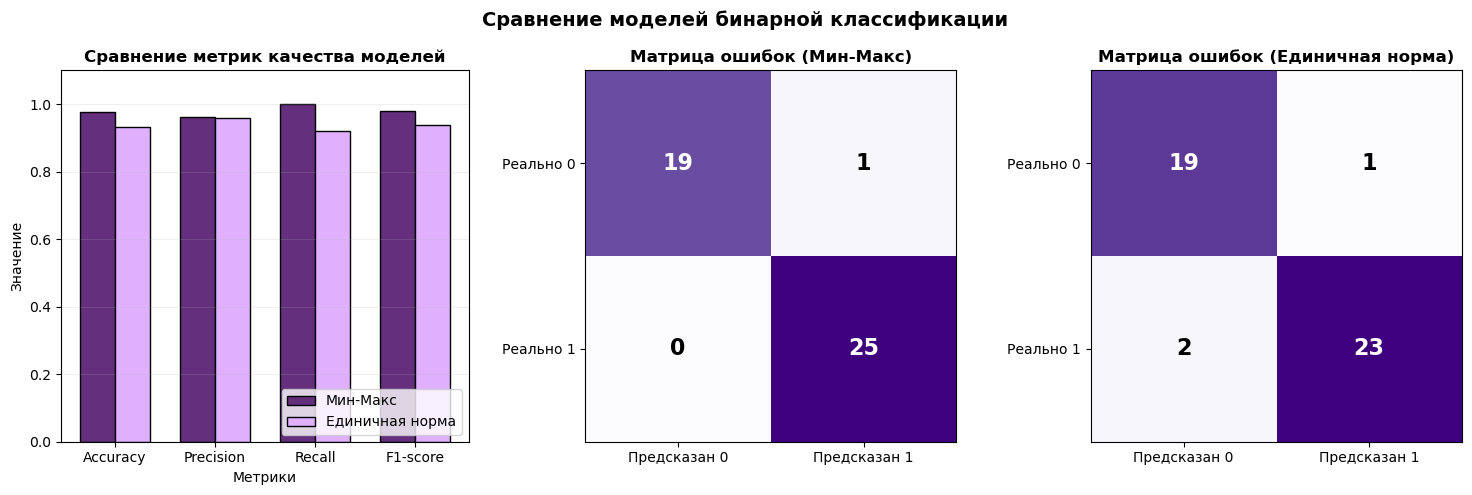

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# График 1: Сравнение метрик (столбчатая диаграмма)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-score']
minmax_values = [acc_mm, prec_mm, rec_mm, f1_mm]
unit_values = [acc_l2, prec_l2, rec_l2, f1_l2]

x = np.arange(len(metrics_names))
width = 0.35

axes[0].bar(x - width/2, minmax_values, width, label='Мин-Макс', color='#642F7D', edgecolor='black')
axes[0].bar(x + width/2, unit_values, width, label='Единичная норма', color='#E0B0FF', edgecolor='black')
axes[0].set_xlabel('Метрики')
axes[0].set_ylabel('Значение')
axes[0].set_title('Сравнение метрик качества моделей', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_names)
axes[0].legend(loc='lower right')
axes[0].set_ylim(0, 1.1)
axes[0].grid(True, alpha=0.2, axis='y')

# График 2: Матрица ошибок (Мин-Макс)
im1 = axes[1].imshow(cm_minmax, cmap='Purples', interpolation='nearest')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['Предсказан 0', 'Предсказан 1'])
axes[1].set_yticklabels(['Реально 0', 'Реально 1'])
axes[1].set_title('Матрица ошибок (Мин-Макс)', fontsize=12, fontweight='bold')
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm_minmax[i, j]), ha='center', va='center', 
                     fontsize=16, fontweight='bold',
                     color='white' if cm_minmax[i, j] > 10 else 'black')

# График 3: Матрица ошибок (Единичная норма)
im2 = axes[2].imshow(cm_unit, cmap='Purples', interpolation='nearest')
axes[2].set_xticks([0, 1])
axes[2].set_yticks([0, 1])
axes[2].set_xticklabels(['Предсказан 0', 'Предсказан 1'])
axes[2].set_yticklabels(['Реально 0', 'Реально 1'])
axes[2].set_title('Матрица ошибок (Единичная норма)', fontsize=12, fontweight='bold')
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, str(cm_unit[i, j]), ha='center', va='center', 
                     fontsize=16, fontweight='bold',
                     color='white' if cm_unit[i, j] > 10 else 'black')

plt.suptitle('Сравнение моделей бинарной классификации', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


> ### **Атрибуты моделей**

In [76]:
print(f"\nМодель (Мин-Макс нормализация):")
print(f" Веса (coef_): {model_mm.coef_[0][:4]}...")        
print(f" Смещение (intercept_): {model_mm.intercept_[0]:.4f}") 
print(f" Количество итераций (n_iter_): {model_mm.n_iter_}")    

print(f"\Модель (Единичная норма):")
print(f" Веса (coef_): {model_l2.coef_[0][:4]}...")       
print(f" Смещение (intercept_): {model_l2.intercept_[0]:.4f}") # model_unit -> model_l2
print(f" Количество итераций (n_iter_): {model_l2.n_iter_}")    # model_unit -> model_l2


Модель (Мин-Макс нормализация):
 Веса (coef_): [-0.00173913  0.03334059 -0.04331694  0.15255814]...
 Смещение (intercept_): -0.0200
 Количество итераций (n_iter_): 17
\Модель (Единичная норма):
 Веса (coef_): [ 0.01182731  0.01481576 -0.02333858  0.08034959]...
 Смещение (intercept_): 0.0200
 Количество итераций (n_iter_): 11


> ### **Предсказания на новых данных**

In [77]:
new_clients = np.array([
    [26, 135000, 210000, 12, 0],
    [23, 69982, 304887, 3, 1],
    [40, 150000, 50000, 25, 1]
])

new_mm = scaler_mm.transform(new_clients)
new_l2 = normalizer.transform(scaler_std.transform(new_clients))

pred_mm_new = model_mm.predict(new_mm)
pred_l2_new = (model_l2.decision_function(new_l2) >= best_thr).astype(int)

print("Клиент | MinMax | UnitNorm")
print("-" * 35)
for i, c in enumerate(new_clients):
    print(f"{c}  |   {pred_mm_new[i]}    |    {pred_l2_new[i]}")

Клиент | MinMax | UnitNorm
-----------------------------------
[    26 135000 210000     12      0]  |   1    |    1
[    23  69982 304887      3      1]  |   0    |    0
[    40 150000  50000     25      1]  |   1    |    1
